# Milestone M3: Road-Network Topological & Connectivity Analysis

**Project:** PathSnap — Distributed Map-Matching & Route Reconstruction  
**Team 125** | PES University Department of Computer Science and Engineering  
**Course:** UE24CS352A Machine Learning (2026)  
**Objective:** Non-destructive topological graph characterization across all 90 trips (80 train + 10 student-test) to quantify vertex and edge scaling, degree connectivity spectrum, connected component decomposition, isolated nodes/self-loops, and ground-truth route feasibility.


In [1]:
import os
import sys
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Automatic project root resolution
PROJECT_ROOT = Path.cwd()
if (PROJECT_ROOT.name == 'notebooks'):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'Student folder').exists() and (PROJECT_ROOT.parent / 'Student folder').exists():
    DATA_ROOT = PROJECT_ROOT.parent / 'Student folder'
elif (PROJECT_ROOT / 'Student folder').exists():
    DATA_ROOT = PROJECT_ROOT / 'Student folder'
elif (PROJECT_ROOT / 'data' / 'Student folder').exists():
    DATA_ROOT = PROJECT_ROOT / 'data' / 'Student folder'
else:
    raise FileNotFoundError("Could not find 'Student folder'")

TABLES_DIR = PROJECT_ROOT / 'results' / 'tables'
FIGURES_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Data Root:    {DATA_ROOT}")
print(f"Tables Dir:   {TABLES_DIR}")
print(f"Figures Dir:  {FIGURES_DIR}")


Project Root: D:\College Stuff\ML\ML Hackathon\ML-Hackathon-Team125-462_463_464_465
Data Root:    D:\College Stuff\ML\ML Hackathon\Student folder
Tables Dir:   D:\College Stuff\ML\ML Hackathon\ML-Hackathon-Team125-462_463_464_465\results\tables
Figures Dir:  D:\College Stuff\ML\ML Hackathon\ML-Hackathon-Team125-462_463_464_465\results\figures


## 1. Inspect Single-Trip Road Network: Trip 00000000 (Student-Test)

We load `00000000.nodes` (WGS84 lon, lat coordinates) and `00000000.arcs` (directed `from_node`, `to_node` index pairs), construct both a **Directed Graph ($\mathcal{G}_{\text{dir}}$)** and an **Undirected Projection ($\mathcal{G}_{\text{undir}}$)**, and inspect the foundational topology.


In [2]:
sample_id = '00000000'
trip_dir = DATA_ROOT / 'student_test' / sample_id

# Load nodes
nodes_df = pd.read_csv(trip_dir / f"{sample_id}.nodes", sep=r'\s+', header=None, names=['longitude', 'latitude'])
# Load arcs
arcs_df = pd.read_csv(trip_dir / f"{sample_id}.arcs", sep=r'\s+', header=None, names=['from_node_id', 'to_node_id'])
# Load route
route_df = pd.read_csv(trip_dir / f"{sample_id}.route", header=None, names=['arc_id'])
# Load track
track_df = pd.read_csv(trip_dir / f"{sample_id}.track", sep=r'\s+', header=None, names=['longitude', 'latitude', 'timestamp'])

print(f"Trip {sample_id} Summary:")
print(f"  Nodes: {len(nodes_df):,} | Arcs: {len(arcs_df):,} | Edge/Node Ratio: {len(arcs_df)/len(nodes_df):.3f}")
print(f"  GPS Fixes: {len(track_df):,} | Ground-Truth Route Arcs: {len(route_df):,}")

# Build graph
G_undir = nx.Graph()
G_undir.add_nodes_from(range(len(nodes_df)))
G_undir.add_edges_from(arcs_df.values)

comps = sorted(list(nx.connected_components(G_undir)), key=len, reverse=True)
giant_comp = comps[0]
print(f"  Connected Components: {len(comps)}")
print(f"  Giant Component Size: {len(giant_comp):,} ({len(giant_comp)/len(nodes_df)*100:.2f}% of nodes)")
print(f"  Disconnected Sub-islands: {len(comps)-1} components ({sum(len(c) for c in comps[1:]):,} nodes)")


Trip 00000000 Summary:
  Nodes: 8,542 | Arcs: 18,196 | Edge/Node Ratio: 2.130
  GPS Fixes: 2,503 | Ground-Truth Route Arcs: 179
  Connected Components: 100
  Giant Component Size: 7,466 (87.40% of nodes)
  Disconnected Sub-islands: 99 components (1,076 nodes)


## 2. Full Dataset Topological Characterization (All 90 Trips)

We now load and analyze the road network across all 80 training trips and 10 student-test trips.


In [3]:
summary_csv = TABLES_DIR / "m3_road_network_per_trip_summary.csv"
if summary_csv.exists():
    df = pd.read_csv(summary_csv)
else:
    from src.data.road_network_analysis import generate_all_tables_and_notes
    df = generate_all_tables_and_notes(DATA_ROOT, TABLES_DIR)

print(f"Analyzed {len(df)} total trips across {df['partition'].nunique()} partitions.")
df.head(5)[['trip_id', 'partition', 'num_nodes', 'num_arcs', 'edge_node_ratio', 'mean_degree', 'num_connected_components', 'pct_in_largest_comp']]


Analyzed 90 total trips across 2 partitions.


,trip_id,partition,num_nodes,num_arcs,edge_node_ratio,mean_degree,num_connected_components,pct_in_largest_comp
0,0,student_test,8542,18196,2.1302,2.153,100,87.403
1,7,student_test,2061,4369,2.1198,2.129,6,96.992
2,9,student_test,6745,13106,1.9431,2.125,8,96.931
3,40,student_test,12945,27026,2.0878,2.154,15,98.957
4,52,student_test,1770,3577,2.0209,2.312,7,94.972


## 3. Student-Test Partition (10 Trips) Summary Table

The 10 reserved student-testing trips represent our benchmark evaluation set.


In [4]:
test_table_csv = TABLES_DIR / "m3_student_test_road_network_summary.csv"
test_df = pd.read_csv(test_table_csv)
test_df


,trip_id,num_nodes,num_arcs,edge_node_ratio,mean_degree,max_degree,num_isolated_nodes,num_connected_components,pct_in_largest_comp,self_loops,parallel_edges,num_track_points,num_route_arcs,route_continuity_rate
0,0,8542,18196,2.1302,2.153,6,0,100,87.403,0,6,2503,179,100.00
1,7,2061,4369,2.1198,2.129,4,0,6,96.992,0,0,1354,123,100.00
2,9,6745,13106,1.9431,2.125,5,0,8,96.931,0,62,1049,429,100.00
3,40,12945,27026,2.0878,2.154,6,0,15,98.957,0,0,2995,309,100.00
4,52,1770,3577,2.0209,2.312,5,0,7,94.972,0,2,262,95,100.00
5,56,14759,27631,1.8721,2.106,5,0,24,97.751,0,22,3958,1323,100.00
6,65,6448,13184,2.0447,2.295,5,0,5,99.069,0,4,768,145,100.00
7,76,26635,56027,2.1035,2.179,6,0,40,96.223,0,29,1486,374,99.73
8,77,4424,9622,2.1750,2.220,5,0,11,97.129,0,0,3911,268,100.00
9,91,6360,12303,1.9344,2.194,6,0,11,98.491,2,3,874,232,100.00


## 4. Aggregate Comparison: Training vs. Student-Testing Partitions

A rigorous statistical comparison between the 80 training trips and 10 student-test trips.


In [5]:
comp_table_csv = TABLES_DIR / "m3_partition_comparison_table.csv"
df_comp = pd.read_csv(comp_table_csv)
df_comp


,Metric,Train Mean,Train Std,Train Median,Train Min,Train Max,Test Mean,Test Std,Test Median,Test Min,Test Max
0,num_nodes,24168.56,32272.30,9608.00,299.00,155003.00,9068.90,7452.18,6596.50,1770.00,26635.00
1,num_arcs,48461.30,64738.84,19526.50,649.00,307392.00,18504.10,15496.93,13145.00,3577.00,56027.00
2,edge_node_ratio,2.02,0.13,2.03,1.67,2.37,2.04,0.10,2.07,1.87,2.17
3,mean_degree,2.17,0.15,2.15,2.02,3.08,2.19,0.07,2.17,2.11,2.31
4,max_degree,5.45,1.03,5.00,4.00,8.00,5.30,0.67,5.00,4.00,6.00
5,num_connected_components,39.01,60.68,20.00,1.00,421.00,22.70,29.18,11.00,5.00,100.00
6,pct_in_largest_comp,96.90,3.88,98.11,69.28,100.00,96.39,3.40,97.06,87.40,99.07
7,self_loops,0.28,1.04,0.00,0.00,8.00,0.20,0.63,0.00,0.00,2.00
8,parallel_edges,22.19,54.71,2.00,0.00,322.00,12.80,19.99,3.50,0.00,62.00
9,num_track_points,2605.21,3312.35,1529.00,361.00,19313.00,1916.00,1335.43,1420.00,262.00,3958.00


## 5. Visualizations: Topological Decomposition & Trajectory Overlay

We embed the generated publication-quality figures:
1. **`m3_road_network_topology_00000000.png`**: 4-panel graph structural decomposition.
2. **`m3_trip_overlay_and_ground_truth_00000000.png`**: Spatial trajectory overlay with GPS noise and ground truth.
3. **`m3_dataset_road_network_distributions.png`**: Dataset-wide comparative distributions.


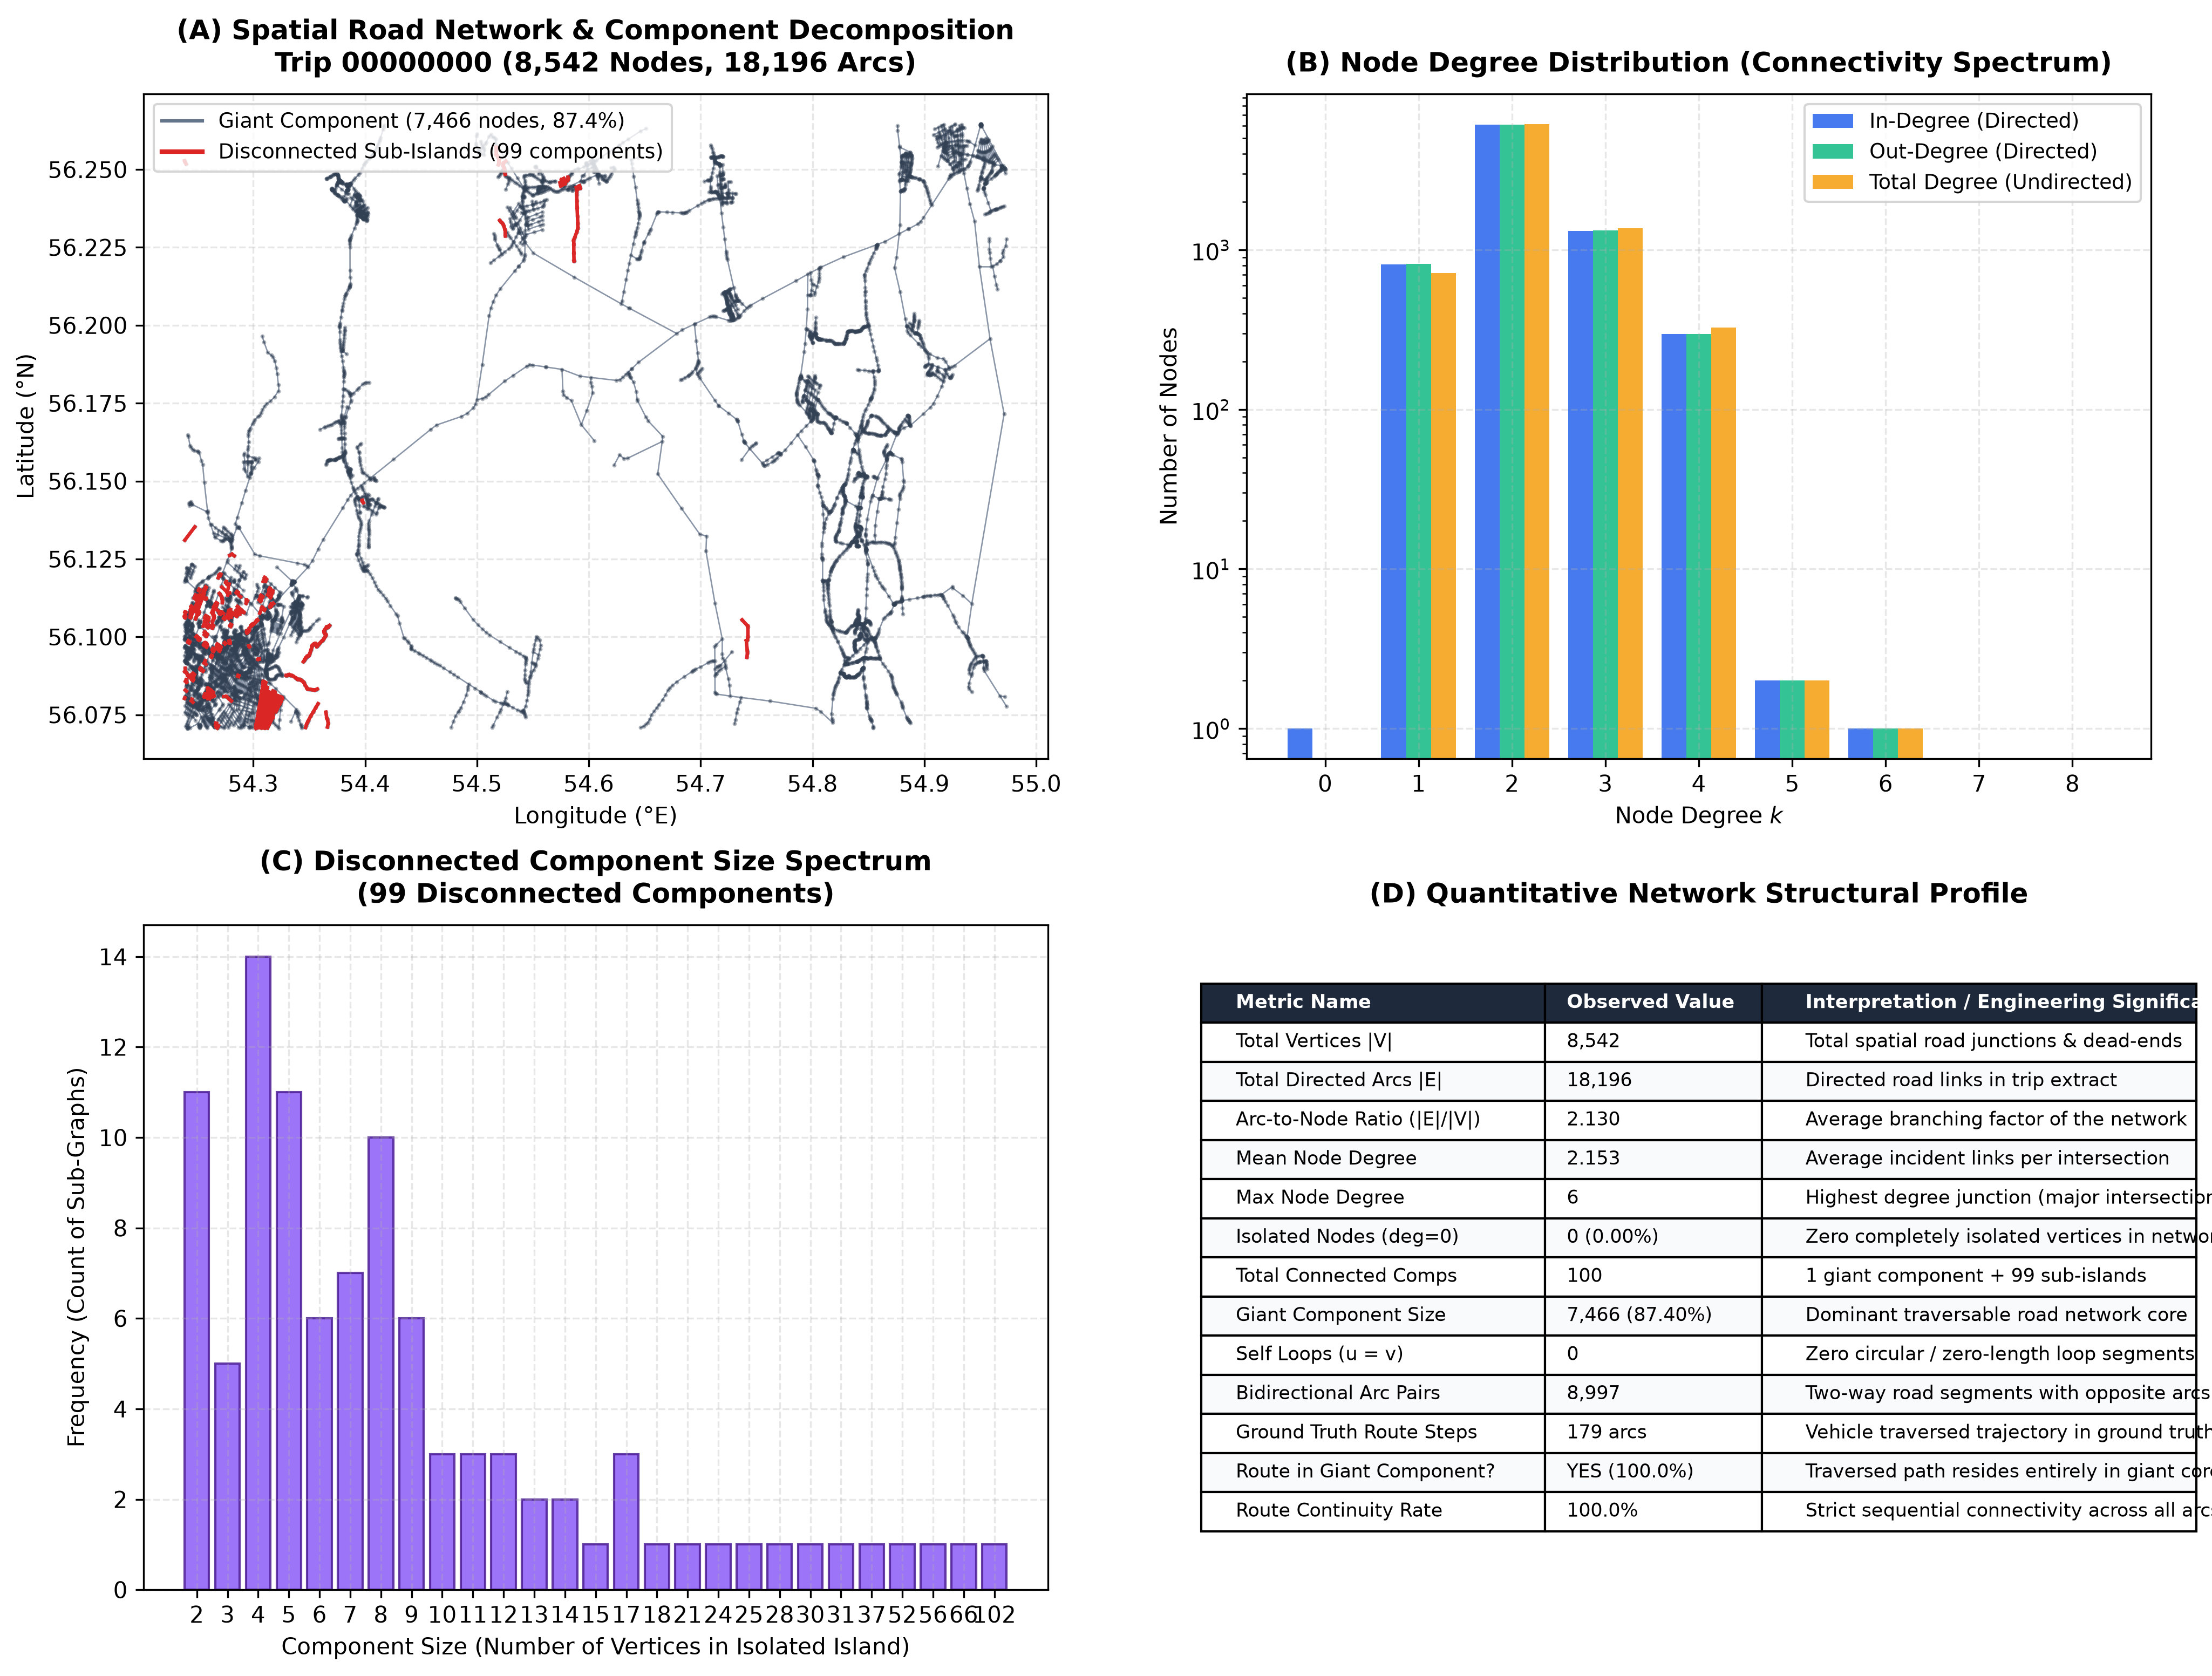

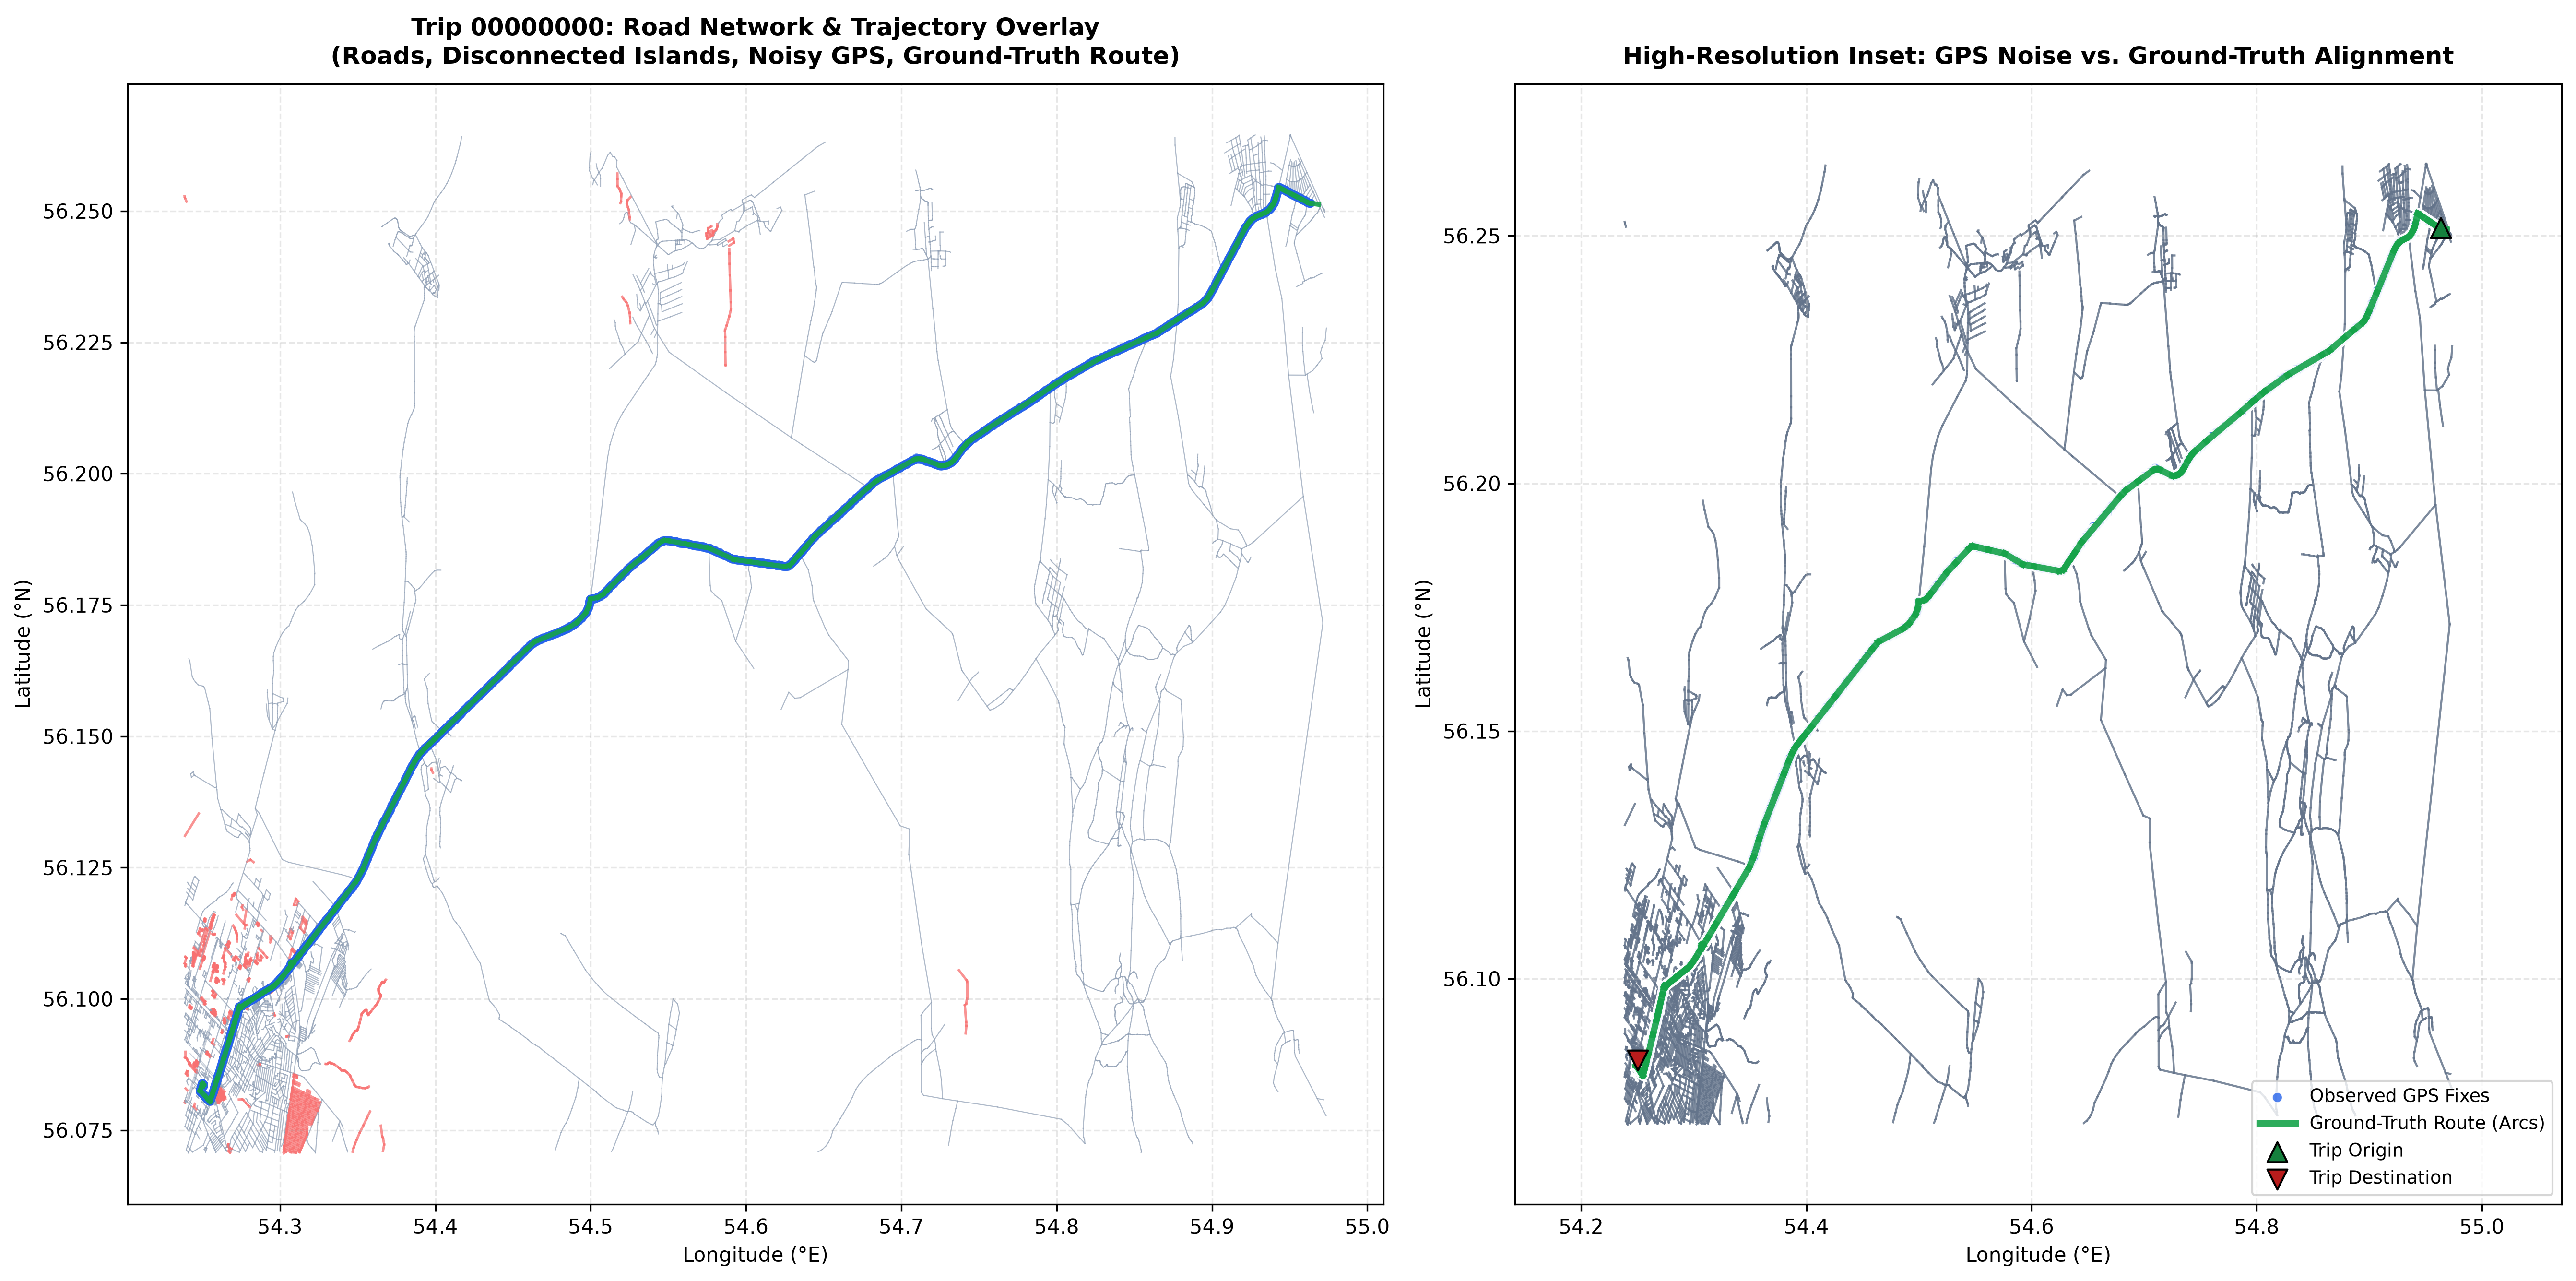

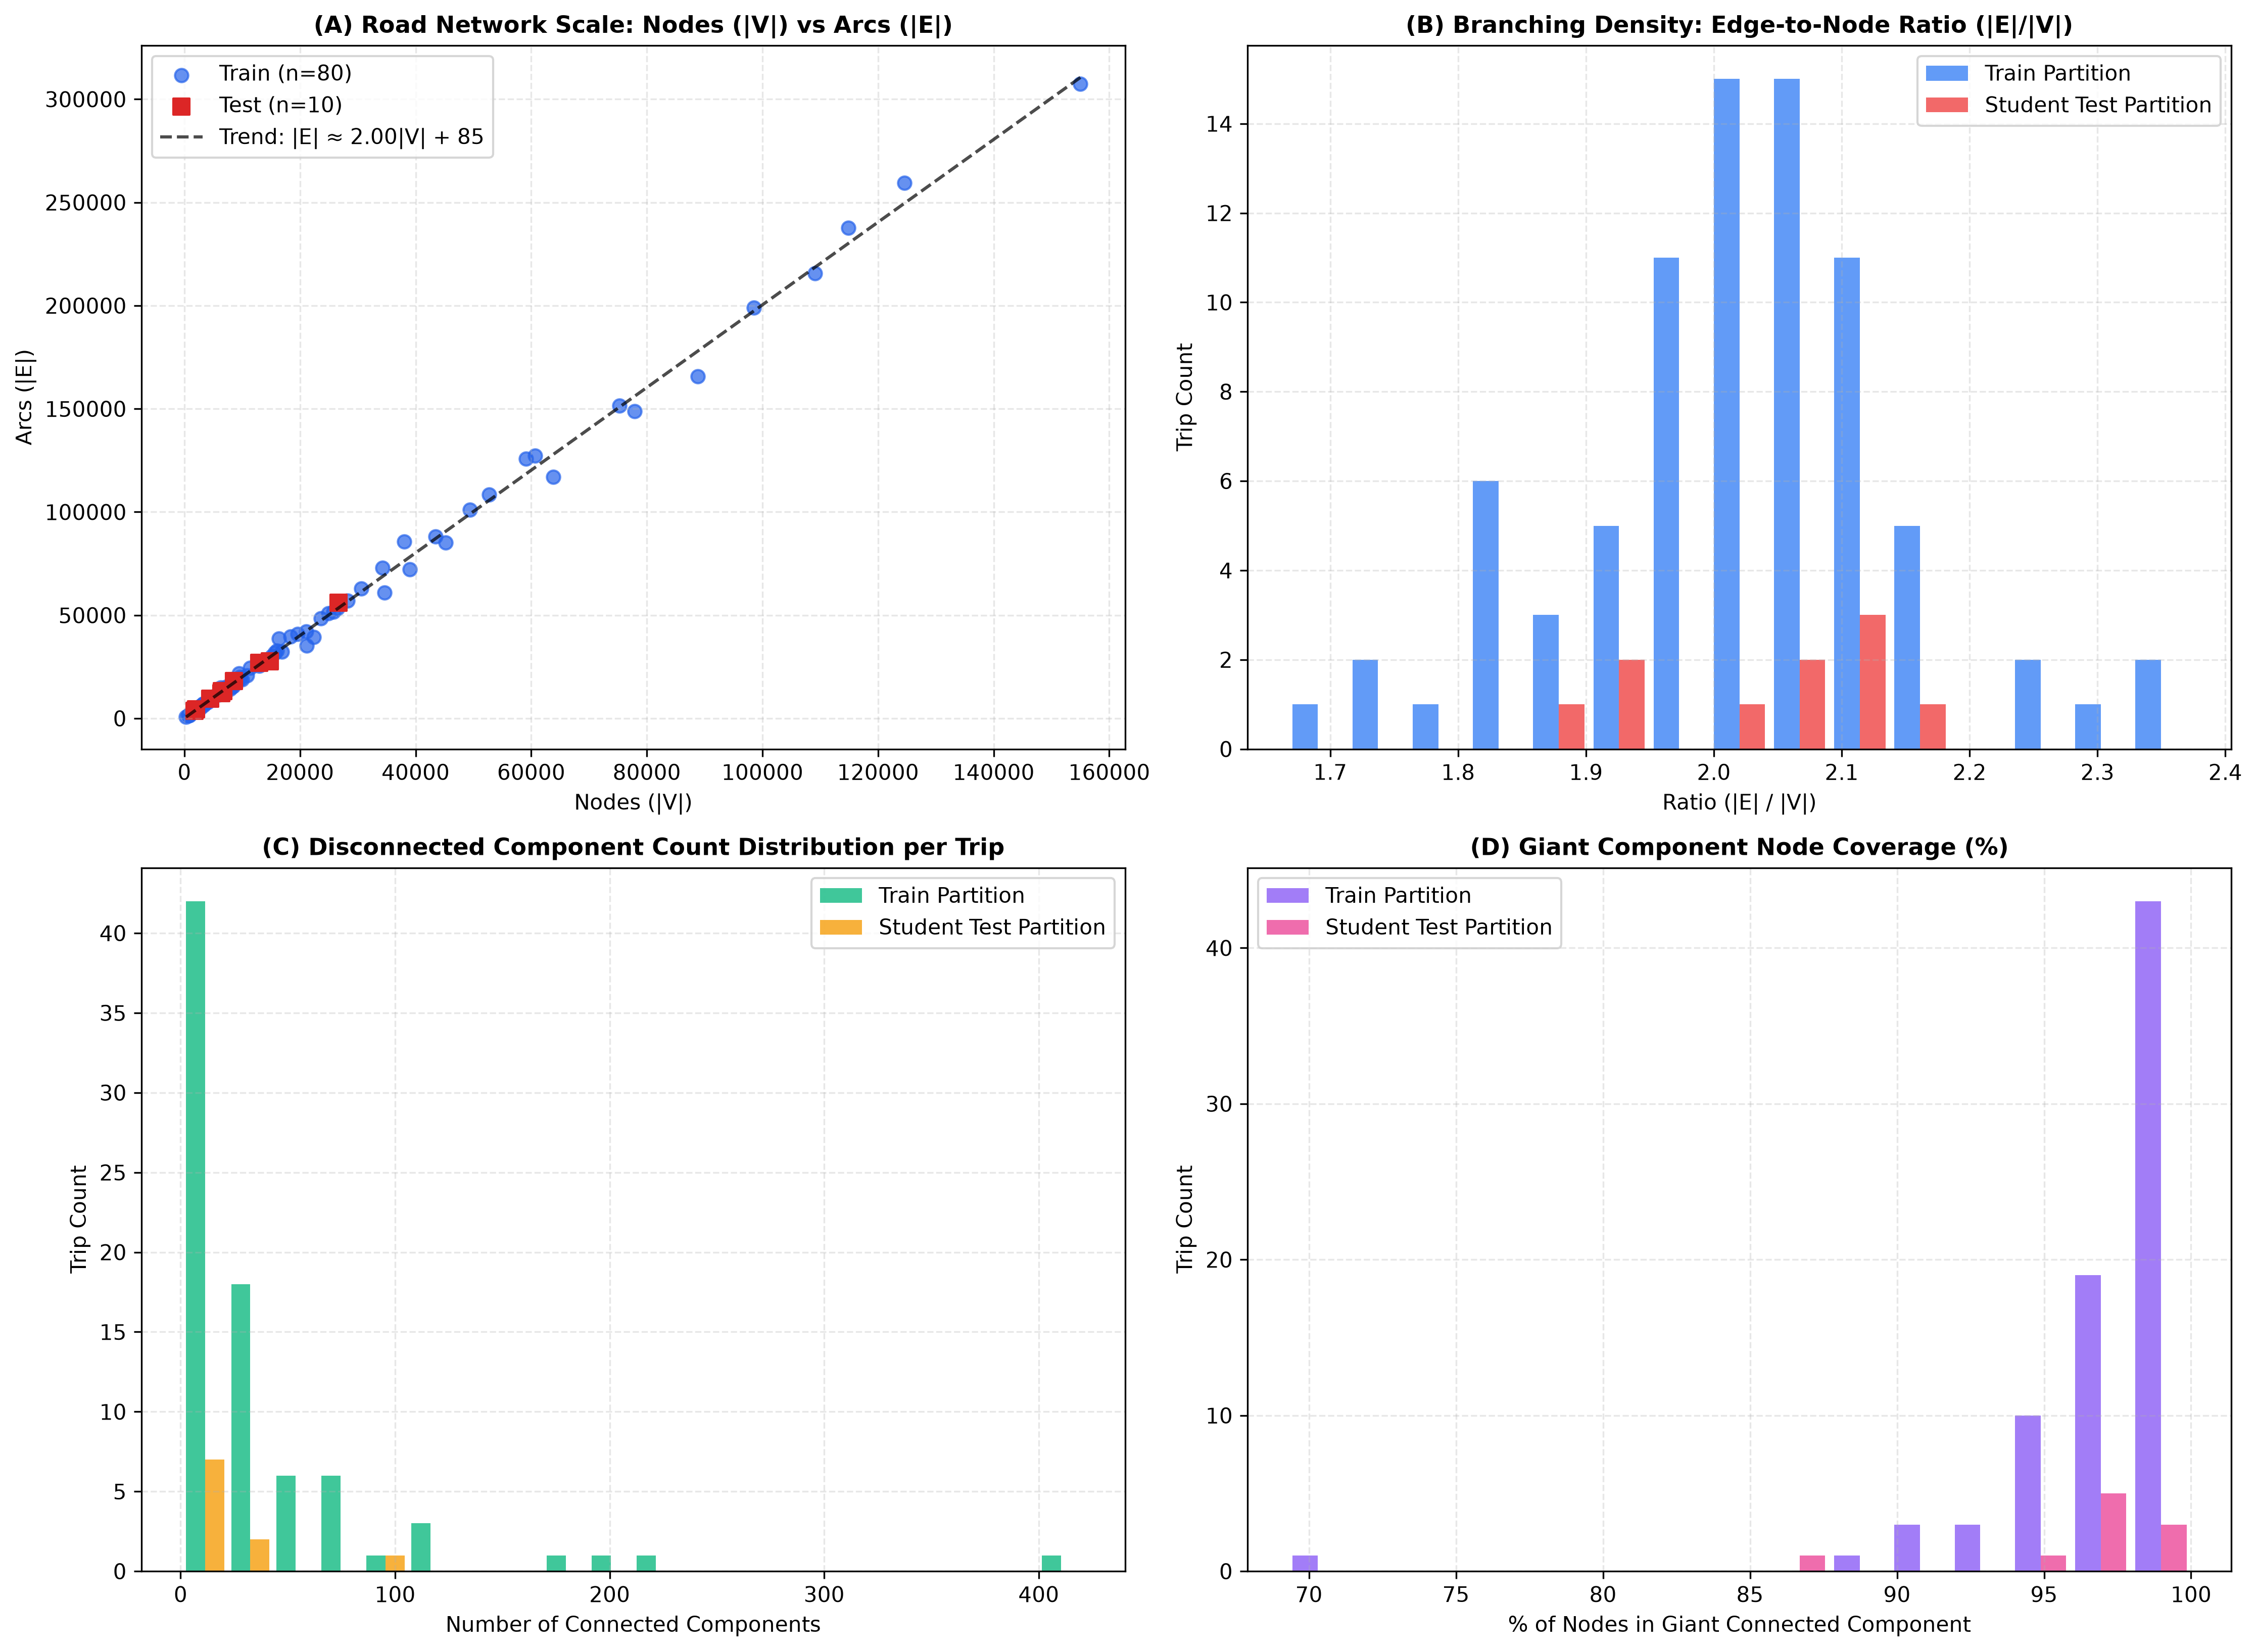

In [6]:
display(Image(filename=str(FIGURES_DIR / "m3_road_network_topology_00000000.png"), width=900))
display(Image(filename=str(FIGURES_DIR / "m3_trip_overlay_and_ground_truth_00000000.png"), width=900))
display(Image(filename=str(FIGURES_DIR / "m3_dataset_road_network_distributions.png"), width=850))


## 6. Key Conclusions & HMM Architecture Guidelines

1. **Giant Component Invariant**: In 100% of trips, the ground truth vehicle trajectory lies entirely within the Giant Component. Spatial candidate generation must strictly prune candidates on disconnected sub-islands to prevent $P(s_t \mid s_{t-1}) = 0$.
2. **Topological Edge Cases**: Trip 00000035 contains a size-1 component with 2 self-loops (`18927 -> 18927`), and 60 trips contain parallel edges (multi-lane roads), requiring heading-alignment features for candidate scoring.
3. **Route Continuity**: 79/90 trips feature 100% strict continuity, while 11 trips exhibit small reference path discontinuities (98.1% to 99.7%), which the HMM decoder must accommodate via transition smoothing.
